# Tables and figures

Builds the ten tables (LaTeX) and the eight figures (PDF and PNG) of the article from the CSV files in `data/colab`
and `data/analysis`, together with the SkinCon annotations that `inconsistency_analysis.ipynb` downloads to
`data/skincon`. The files are written to `output/tables` and `output/figures`. The figures use the font
Liberation Sans.

In [1]:
from pathlib import Path
import logging
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.transforms import blended_transform_factory
from sklearn.metrics import roc_curve
from IPython.display import Image, display

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

DATA = Path("data")
SKINCON, COLAB, ANALYSIS = DATA / "skincon", DATA / "colab", DATA / "analysis"
TABLES, FIGURES = Path("output/tables"), Path("output/figures")
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)


def read(path, **kw):
    return pd.read_csv(path, float_precision="round_trip", **kw)


counts = read(COLAB / "clean_counts.csv").set_index("quantity").value
settings = read(COLAB / "cleaning_settings.csv").set_index("setting").value
E = read(COLAB / "vocabulary.csv").concept.tolist()
SKINCON_URL = "https://skincon-dataset.github.io/files"
SKINCON.mkdir(parents=True, exist_ok=True)
for name in ["annotations_fitzpatrick17k.csv", "annotations_ddi.csv"]:
    if not (SKINCON / name).exists():
        urllib.request.urlretrieve(f"{SKINCON_URL}/{name}", SKINCON / name)


def concept_key(name):
    key = "".join(ch.lower() if ch.isalnum() else "_" for ch in name)
    while "__" in key:
        key = key.replace("__", "_")
    return key.strip("_")


fitz = read(SKINCON / "annotations_fitzpatrick17k.csv")
ddi = read(SKINCON / "annotations_ddi.csv")
fitz["image_id"] = "fitz_" + fitz.ImageID.str.replace(".jpg", "", regex=False)
ddi["image_id"] = "ddi_" + ddi.ImageID.astype(str)
annotations = pd.concat([fitz, ddi]).rename(columns=concept_key)
images = read(ANALYSIS / "clean_dataset.csv").merge(annotations[["image_id"] + E], on="image_id", how="left", validate="one_to_one")
images[E] = images[E].fillna(0).astype(int)
y = images.y.values
n_img, n_mal = len(images), int(y.sum())
FILTERS = ["none", "symmetric", "asymmetric", "majority", "weighted", "tau"]
FILTER_NAMES = {"none": "None", "symmetric": "Symmetric removal", "asymmetric": "Asymmetric removal",
                "majority": "Majority editing", "weighted": "Weighted editing", "tau": "$\\tau$-editing"}
GROUPS = ["BCC", "SCC", "Melanoma", "Cutaneous lymphoma", "Actinic keratosis", "Kaposi sarcoma"]
MODELS = ["hard", "soft", "hybrid"]

## Tables

In [2]:
def thousands(n):
    return f"{int(n):,}"


def percent(x, k=1):
    return f"{100 * x:.{k}f}\\%"


def write_table(label, caption, body, size="small"):
    tex = f"\\begin{{table}}[tbp]\n\\centering\\{size}\n\\caption{{{caption}}}\\label{{{label}}}\n{body}\\end{{table}}\n"
    (TABLES / (label.replace(":", "_") + ".tex")).write_text(tex)
    print(tex)


tau_group, tau_duplicate = float(settings["tau_group"]), float(settings["tau_duplicate"])

Table 1, data quality audit.

In [3]:
by_threshold = read(COLAB / "duplicate_pairs_by_threshold.csv").set_index("threshold")
removal = read(COLAB / "removal_by_subgroup.csv")
malignant = removal[removal.attribute == "malignant"].set_index("level")
skin = removal[removal.attribute == "skin_type"]
partition = images.partition.value_counts()
r90, r95 = by_threshold.loc[tau_group], by_threshold.loc[tau_duplicate]
rows = [
    ("Annotated images (Fitzpatrick17k, DDI)",
     f'{thousands(counts["fitzpatrick17k_annotated"] + counts["ddi_annotated"])} ({thousands(counts["fitzpatrick17k_annotated"])}, {counts["ddi_annotated"]})'),
    ("Images after annotator exclusions and quality control", thousands(counts["images_found"])),
    ("Candidate near-copy pairs", thousands(counts["candidate_pairs"])),
    (f"Pairs with cosine $\\ge {tau_group:.2f}$ (diagnosis differs, malignancy differs)",
     f'{int(r90.pairs)} ({int(r90["diagnosis differs (D)"])}, {int(r90["malignancy differs"])})'),
    (f"Pairs with cosine $\\ge {tau_duplicate:.2f}$ (diagnosis differs, malignancy differs)",
     f'{int(r95.pairs)} ({int(r95["diagnosis differs (D)"])}, {int(r95["malignancy differs"])})'),
    ("Confirmed duplicate pairs", str(counts["confirmed_duplicate_pairs"])),
    ("Confirmed pairs with conflicting malignancy labels", str(counts["clusters_conflicting_malignancy"])),
    ("Confirmed pairs with conflicting concept vectors", str(counts["clusters_conflicting_concepts"])),
    (f"Unconfirmed pairs with cosine $\\ge {tau_duplicate:.2f}$ left for visual review", str(counts["unconfirmed_pairs_for_review"])),
    ("Removal rate of malignant and non-malignant images ($p$)",
     f'{percent(malignant.removal_rate["1"], 2)}, {percent(malignant.removal_rate["0"], 2)} ({malignant.chi2_p_value["1"]:.3f})'),
    ("Removal rate across Fitzpatrick skin types ($p$)",
     f"{percent(skin.removal_rate.min(), 0)} to {percent(skin.removal_rate.max(), 1)} ({skin.chi2_p_value.iloc[0]:.2f})"),
    ("Near-copy pairs across splits, earlier split file", str(counts.get("near_copy_pairs_across_earlier_split", "--"))),
    ("Near-copy groups across splits, present split", str(counts["groups_across_splits"])),
    ("Clean images (malignant, benign, non-neoplastic)",
     f'{thousands(counts["clean_images"])} ({partition["malignant"]}, {partition["benign"]}, {thousands(partition["non-neoplastic"])})'),
]
body = ("\\begin{tabular}{lr}\n\\toprule\nQuantity & Value\\\\\n\\midrule\n" + "".join(f"{a} & {b}\\\\\n" for a, b in rows)
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:audit", "Data quality audit of the SkinCon images. We define near copies as pairs whose DINOv2 embeddings reach a "
            f"cosine similarity of {tau_group:.2f} or whose perceptual hashes differ by at most 10 bits. Confirmed duplicates satisfy "
            "both detectors, or a single detector at a strict threshold, while the $p$-values come from chi-square tests of the "
            "removal rates across subgroups.", body)

\begin{table}[tbp]
\centering\small
\caption{Data quality audit of the SkinCon images. We define near copies as pairs whose DINOv2 embeddings reach a cosine similarity of 0.90 or whose perceptual hashes differ by at most 10 bits. Confirmed duplicates satisfy both detectors, or a single detector at a strict threshold, while the $p$-values come from chi-square tests of the removal rates across subgroups.}\label{tab:audit}
\begin{tabular}{lr}
\toprule
Quantity & Value\\
\midrule
Annotated images (Fitzpatrick17k, DDI) & 4,346 (3,690, 656)\\
Images after annotator exclusions and quality control & 3,863\\
Candidate near-copy pairs & 475\\
Pairs with cosine $\ge 0.90$ (diagnosis differs, malignancy differs) & 453 (207, 46)\\
Pairs with cosine $\ge 0.95$ (diagnosis differs, malignancy differs) & 105 (7, 0)\\
Confirmed duplicate pairs & 30\\
Confirmed pairs with conflicting malignancy labels & 0\\
Confirmed pairs with conflicting concept vectors & 19\\
Unconfirmed pairs with cosine $\ge 0.95$ l

Table 2, rough-set quantities of the four vocabularies.

In [4]:
vocabularies = read(ANALYSIS / "vocabularies.csv").set_index("vocabulary")
V = ["A48", "E24", "V20", "V12"]
voc = lambda column: [vocabularies.loc[v, column] for v in V]
lines = [
    ("Concepts", [str(int(c)) for c in voc("concepts")]),
    ("Profiles", [str(int(c)) for c in voc("profiles")]),
    ("Inconsistent profiles", [str(int(c)) for c in voc("inconsistent_profiles")]),
    ("Boundary images", [f"{thousands(b)} ({percent(b / n_img)})" for b in voc("boundary_images")]),
    ("Quality of classification $\\gamma$", [f"{x:.3f}" for x in voc("gamma")]),
    ("Malignant images in the boundary", [percent(x) for x in voc("malignant_in_boundary")]),
    ("Non-malignant images in the boundary", [percent(x) for x in voc("non_malignant_in_boundary")]),
    ("Accuracy ceiling $\\mathrm{acc}^*$", [f"{x:.3f}" for x in voc("acc_ceiling")]),
    ("Balanced accuracy ceiling $\\mathrm{BA}^*$", [f"{x:.3f}" for x in voc("ba_ceiling")]),
    ("AUROC ceiling $\\mathrm{AUC}^*$", [f"{x:.3f}" for x in voc("auroc_ceiling")]),
    ("Label information captured", [percent(x) for x in voc("label_information")]),
    ("Lower bound on the error $P_e^*$", [f"{x:.3f}" for x in voc("fano_bound")]),
    ("Singleton mass", [percent(x) for x in voc("singleton_mass")]),
    ("LOO AUROC of the profile rate", [f"{x:.3f}" for x in voc("loo_auroc")]),
    ("CV AUROC of logistic regression", [f"{x:.3f}" for x in voc("cv_auroc")]),
]
body = ("\\setlength{\\tabcolsep}{4pt}\n\\begin{tabular}{lrrrr}\n\\toprule\nMeasure & A48 & E24 & V20 & V12\\\\\n\\midrule\n"
        + "".join(f"{a} & " + " & ".join(b) + " \\\\\n" for a, b in lines) + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:vocab", "Rough-set quantities of the clean dataset for four vocabularies. The leave-one-out (LOO) score of an image "
            "is the smoothed malignant rate of the other images of its profile. The cross-validated (CV) AUROC is the mean over 20 "
            "folds of an L2-regularized logistic regression on the concepts.", body)

\begin{table}[tbp]
\centering\small
\caption{Rough-set quantities of the clean dataset for four vocabularies. The leave-one-out (LOO) score of an image is the smoothed malignant rate of the other images of its profile. The cross-validated (CV) AUROC is the mean over 20 folds of an L2-regularized logistic regression on the concepts.}\label{tab:vocab}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{lrrrr}
\toprule
Measure & A48 & E24 & V20 & V12\\
\midrule
Concepts & 48 & 24 & 20 & 12 \\
Profiles & 867 & 637 & 549 & 277 \\
Inconsistent profiles & 114 & 118 & 122 & 93 \\
Boundary images & 2,469 (64.4\%) & 2,753 (71.8\%) & 2,891 (75.4\%) & 3,390 (88.4\%) \\
Quality of classification $\gamma$ & 0.356 & 0.282 & 0.246 & 0.116 \\
Malignant images in the boundary & 68.3\% & 74.9\% & 78.3\% & 92.5\% \\
Non-malignant images in the boundary & 63.6\% & 71.2\% & 74.8\% & 87.6\% \\
Accuracy ceiling $\mathrm{acc}^*$ & 0.890 & 0.880 & 0.876 & 0.851 \\
Balanced accuracy ceiling $\mathrm{BA}^*$ & 0.781 & 0.7

Table 3, concepts.

In [5]:
concepts = read(ANALYSIS / "concepts.csv")
extra = concepts[~concepts.in_E24 & (concepts.images >= 20)].sort_values("mutual_information_mbit", ascending=False).head(4)
shown = pd.concat([concepts[concepts.in_E24], extra]).sort_values("mutual_information_mbit", ascending=False)


def concept_label(s):
    s = s.replace("(", " ").replace(")", "").replace("/", " or ").replace("  ", " ").strip()
    return s[0] + s[1:].lower()


yes = lambda b: "yes" if b else "no"
body = ("\\setlength{\\tabcolsep}{3pt}\n\\begin{tabular}{lrrlrrrrcc}\n\\toprule\n"
        "Concept & Images & Train & Malignant rate & Odds ratio & MI (mbit) & Boundary & Consistent & E24 & V20\\\\\n\\midrule\n"
        + "".join(f"{concept_label(r.name)} & {thousands(r.images)} & {thousands(r.train_images)} & "
                  f"{r.malignant_rate:.2f} [{r.rate_low:.2f}, {r.rate_high:.2f}] & {r.odds_ratio:.2f} & {r.mutual_information_mbit:.1f} & "
                  f"{r.boundary_share:.3f} & {r.consistent_share:.3f} & {yes(r.in_E24)} & {yes(r.in_V20)} \\\\\n"
                  for r in shown.itertuples())
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:concepts", "Concepts of E24 together with the four most informative concepts outside it that occur on at least 20 "
            "images, sorted by mutual information (MI) with malignancy in millibits (mbit). Malignant rates carry 95\\% Wilson "
            "intervals, while the boundary and consistent columns give the share of images in each region that carry the concept "
            "of the row.", body, size="scriptsize")

\begin{table}[tbp]
\centering\scriptsize
\caption{Concepts of E24 together with the four most informative concepts outside it that occur on at least 20 images, sorted by mutual information (MI) with malignancy in millibits (mbit). Malignant rates carry 95\% Wilson intervals, while the boundary and consistent columns give the share of images in each region that carry the concept of the row.}\label{tab:concepts}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lrrlrrrrcc}
\toprule
Concept & Images & Train & Malignant rate & Odds ratio & MI (mbit) & Boundary & Consistent & E24 & V20\\
\midrule
Crust & 548 & 321 & 0.33 [0.29, 0.37] & 3.06 & 20.0 & 0.118 & 0.206 & yes & yes \\
Telangiectasia & 104 & 53 & 0.61 [0.51, 0.69] & 8.40 & 19.9 & 0.016 & 0.055 & yes & yes \\
Black & 118 & 59 & 0.52 [0.43, 0.61] & 5.82 & 15.0 & 0.026 & 0.043 & yes & yes \\
Ulcer & 167 & 99 & 0.37 [0.30, 0.45] & 3.18 & 8.0 & 0.024 & 0.094 & yes & yes \\
Translucent & 23 & 14 & 0.78 [0.58, 0.90] & 17.33 & 8.0 & 0.004 & 0.01

Table 4, forced misses per malignant group.

In [6]:
groups = read(ANALYSIS / "malignant_groups.csv").set_index("malignant_group")
weighted = lambda column: (groups[column] * groups.images).sum() / groups.images.sum()
everything = {"images": int(groups.images.sum()), "test_images": int(groups.test_images.sum()), "boundary_share": weighted("boundary_share"),
              "forced_miss_share": weighted("forced_miss_share"), "forced_miss_share_A48": weighted("forced_miss_share_A48")}
row = lambda name, r: (f'{name} & {int(r["images"])} & {int(r["test_images"])} & {percent(r["boundary_share"])} & '
                       f'{percent(r["forced_miss_share"])} & {percent(r["forced_miss_share_A48"])} \\\\\n')
body = ("\\begin{tabular}{lrrrrr}\n\\toprule\nGroup & Images & Test & Boundary & Forced misses, E24 & Forced misses, A48\\\\\n\\midrule\n"
        + row("All malignant", everything) + "".join(row(g, groups.loc[g]) for g in GROUPS + ["Other"])
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:fam", f"Forced misses of each malignant group on all {thousands(n_img)} images under the E24 vocabulary. For "
            "comparison, the last column repeats the analysis with all 48 concepts.", body)

\begin{table}[tbp]
\centering\small
\caption{Forced misses of each malignant group on all 3,833 images under the E24 vocabulary. For comparison, the last column repeats the analysis with all 48 concepts.}\label{tab:fam}
\begin{tabular}{lrrrrr}
\toprule
Group & Images & Test & Boundary & Forced misses, E24 & Forced misses, A48\\
\midrule
All malignant & 637 & 125 & 74.9\% & 26.1\% & 23.9\% \\
BCC & 189 & 42 & 69.3\% & 25.4\% & 21.2\% \\
SCC & 171 & 33 & 65.5\% & 17.0\% & 15.2\% \\
Melanoma & 126 & 20 & 79.4\% & 22.2\% & 21.4\% \\
Cutaneous lymphoma & 79 & 13 & 94.9\% & 44.3\% & 39.2\% \\
Actinic keratosis & 33 & 5 & 75.8\% & 24.2\% & 30.3\% \\
Kaposi sarcoma & 32 & 9 & 87.5\% & 43.8\% & 43.8\% \\
Other & 7 & 3 & 85.7\% & 57.1\% & 57.1\% \\
\bottomrule
\end{tabular}
\end{table}



Table 5, filters.

In [7]:
training = read(ANALYSIS / "filter_training.csv").set_index("filter")
oof = read(ANALYSIS / "filter_out_of_fold.csv").set_index("filter")
names = {**FILTER_NAMES}
kept0 = training.train_malignant_kept["none"]
body = ("\\setlength{\\tabcolsep}{3.5pt}\n\\resizebox{\\linewidth}{!}{\\begin{tabular}{lrrrccccc}\n\\toprule\n"
        "& \\multicolumn{3}{c}{Training split} & \\multicolumn{4}{c}{Out-of-fold, unfiltered} & Filtered\\\\\n"
        "\\cmidrule(lr){2-4}\\cmidrule(lr){5-8}\\cmidrule(lr){9-9}\n"
        f"Filter & Images & Malignant kept & $\\gamma$ & AUROC & Sensitivity & Specificity & Missed (of {n_mal}) & AUROC\\\\\n\\midrule\n"
        + "".join(f"{names[h]} & {thousands(training.train_images_kept[h])} & {int(training.train_malignant_kept[h])} "
                  f"({100 * training.train_malignant_kept[h] / kept0:.0f}\\%) & {training.train_gamma[h]:.3f} & "
                  f"{oof.auroc[h]:.3f} & {oof.sensitivity[h]:.3f} & {oof.specificity[h]:.3f} & "
                  f"{round((1 - oof.sensitivity[h]) * n_mal)} & {training.filtered_cv_auroc[h]:.3f} \\\\\n" for h in FILTERS)
        + "\\bottomrule\n\\end{tabular}}\n")
write_table("tab:filter", "Effect of the filters. The training columns refer to the fixed training split, whereas the out-of-fold "
            f"columns score all {thousands(n_img)} unfiltered images at a threshold of 0.5. The last column gives the mean AUROC on "
            "test folds that passed through the same filter.", body)

\begin{table}[tbp]
\centering\small
\caption{Effect of the filters. The training columns refer to the fixed training split, whereas the out-of-fold columns score all 3,833 unfiltered images at a threshold of 0.5. The last column gives the mean AUROC on test folds that passed through the same filter.}\label{tab:filter}
\setlength{\tabcolsep}{3.5pt}
\resizebox{\linewidth}{!}{\begin{tabular}{lrrrccccc}
\toprule
& \multicolumn{3}{c}{Training split} & \multicolumn{4}{c}{Out-of-fold, unfiltered} & Filtered\\
\cmidrule(lr){2-4}\cmidrule(lr){5-8}\cmidrule(lr){9-9}
Filter & Images & Malignant kept & $\gamma$ & AUROC & Sensitivity & Specificity & Missed (of 637) & AUROC\\
\midrule
None & 2,318 & 354 (100\%) & 0.312 & 0.749 & 0.626 & 0.754 & 238 & 0.754 \\
Symmetric removal & 724 & 104 (29\%) & 1.000 & 0.710 & 0.438 & 0.881 & 358 & 0.891 \\
Asymmetric removal & 974 & 354 (100\%) & 1.000 & 0.661 & 0.882 & 0.291 & 75 & 0.814 \\
Majority editing & 2,073 & 117 (33\%) & 1.000 & 0.711 & 0.377 & 0.906 &

Table 6, test results of the concept bottleneck models.

In [8]:
summary = read(COLAB / "summary_test.csv")
summary = summary[summary.source == "all"].set_index("model")
n_test = int((images.split == "test").sum())
columns = ["auroc", "balanced_accuracy", "macro_f1", "sensitivity", "specificity"]
body = ("\\begin{tabular}{lccccc}\n\\toprule\nModel & AUROC & Balanced accuracy & Macro F1 & Sensitivity & Specificity\\\\\n\\midrule\n"
        + "".join(f"{m.capitalize()} & " + " & ".join(f'{summary[c + "_mean"][m]:.3f} $\\pm$ {summary[c + "_std"][m]:.3f}' for c in columns)
                  + " \\\\\n" for m in ["hard", "hybrid", "soft"])
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:cbm", f"Test results on the {n_test} unfiltered test images at the default threshold, given as means and standard "
            "deviations over three seeds. Macro F1 is the mean over both classes of the F1 score, which is the harmonic mean of "
            "precision and sensitivity.", body)

\begin{table}[tbp]
\centering\small
\caption{Test results on the 720 unfiltered test images at the default threshold, given as means and standard deviations over three seeds. Macro F1 is the mean over both classes of the F1 score, which is the harmonic mean of precision and sensitivity.}\label{tab:cbm}
\begin{tabular}{lccccc}
\toprule
Model & AUROC & Balanced accuracy & Macro F1 & Sensitivity & Specificity\\
\midrule
Hard & 0.795 $\pm$ 0.008 & 0.719 $\pm$ 0.013 & 0.622 $\pm$ 0.031 & 0.763 $\pm$ 0.036 & 0.675 $\pm$ 0.060 \\
Hybrid & 0.813 $\pm$ 0.020 & 0.732 $\pm$ 0.020 & 0.635 $\pm$ 0.043 & 0.776 $\pm$ 0.071 & 0.687 $\pm$ 0.086 \\
Soft & 0.834 $\pm$ 0.006 & 0.752 $\pm$ 0.009 & 0.662 $\pm$ 0.004 & 0.779 $\pm$ 0.040 & 0.726 $\pm$ 0.021 \\
\bottomrule
\end{tabular}
\end{table}



Table 7, operating points.

In [9]:
points = read(ANALYSIS / "operating_points.csv")
malignant_test = int(images[images.split == "test"].y.sum())
g = points.groupby(["target", "model"])
mean_sd = lambda t, m, c: f"{g[c].mean()[(t, m)]:.3f} $\\pm$ {g[c].std()[(t, m)]:.3f}"
label = {0.0: "Default (logit 0)", 0.9: "90\\% validation sensitivity", 0.95: "95\\% validation sensitivity"}
blocks = []
for t in (0.0, 0.9, 0.95):
    blocks.append("".join(
        f'{label[t] if i == 0 else ""} & {m.capitalize()} & {mean_sd(t, m, "sensitivity")} & '
        f'{(1 - g.sensitivity.mean()[(t, m)]) * malignant_test:.1f} & {mean_sd(t, m, "specificity")} & '
        f'{mean_sd(t, m, "fpr_benign")} & {mean_sd(t, m, "fpr_non-neoplastic")} \\\\\n' for i, m in enumerate(MODELS)))
body = ("\\setlength{\\tabcolsep}{3.5pt}\n\\resizebox{\\linewidth}{!}{\\begin{tabular}{llccccc}\n\\toprule\n"
        f"Threshold & Model & Sensitivity & Missed (of {malignant_test}) & Specificity & FPR benign & FPR non-neoplastic\\\\\n\\midrule\n"
        + "\\addlinespace\n".join(blocks) + "\\bottomrule\n\\end{tabular}}\n")
write_table("tab:op", "Operating points on the test split, with thresholds set on the validation images of each seed. Values are "
            "means and standard deviations over three seeds, while the last two columns give the false positive rate (FPR) on "
            "benign and non-neoplastic test images.", body)

\begin{table}[tbp]
\centering\small
\caption{Operating points on the test split, with thresholds set on the validation images of each seed. Values are means and standard deviations over three seeds, while the last two columns give the false positive rate (FPR) on benign and non-neoplastic test images.}\label{tab:op}
\setlength{\tabcolsep}{3.5pt}
\resizebox{\linewidth}{!}{\begin{tabular}{llccccc}
\toprule
Threshold & Model & Sensitivity & Missed (of 125) & Specificity & FPR benign & FPR non-neoplastic\\
\midrule
Default (logit 0) & Hard & 0.763 $\pm$ 0.036 & 29.7 & 0.675 $\pm$ 0.060 & 0.489 $\pm$ 0.089 & 0.256 $\pm$ 0.050 \\
 & Soft & 0.779 $\pm$ 0.040 & 27.7 & 0.726 $\pm$ 0.021 & 0.451 $\pm$ 0.077 & 0.200 $\pm$ 0.004 \\
 & Hybrid & 0.776 $\pm$ 0.071 & 28.0 & 0.687 $\pm$ 0.086 & 0.483 $\pm$ 0.103 & 0.241 $\pm$ 0.080 \\
\addlinespace
90\% validation sensitivity & Hard & 0.925 $\pm$ 0.023 & 9.3 & 0.424 $\pm$ 0.038 & 0.744 $\pm$ 0.041 & 0.505 $\pm$ 0.037 \\
 & Soft & 0.912 $\pm$ 0.032 & 11

Table 8, non-malignant diagnoses flagged at the 95% sensitivity threshold.

In [10]:
flagged = read(ANALYSIS / "flagged_diagnoses.csv")
wide = flagged.pivot(index="diagnosis", columns="model", values="flag_rate")
n_dx = flagged.groupby("diagnosis").test_images.first()
wide["mean"] = wide[MODELS].mean(axis=1)
wide = wide.sort_values("mean", ascending=False, kind="stable").head(8)
body = ("\\begin{tabular}{lrccc}\n\\toprule\nDiagnosis & Test images & Hard & Soft & Hybrid\\\\\n\\midrule\n"
        + "".join(f"{dx[0].upper() + dx[1:]} & {n_dx[dx]} & {r.hard:.2f} & {r.soft:.2f} & {r.hybrid:.2f} \\\\\n" for dx, r in wide.iterrows())
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:fpcost", "Non-malignant diagnoses with at least five test images that are most often flagged at the 95\\% "
            "sensitivity threshold. Values are flag rates averaged over three seeds.", body)

\begin{table}[tbp]
\centering\small
\caption{Non-malignant diagnoses with at least five test images that are most often flagged at the 95\% sensitivity threshold. Values are flag rates averaged over three seeds.}\label{tab:fpcost}
\begin{tabular}{lrccc}
\toprule
Diagnosis & Test images & Hard & Soft & Hybrid\\
\midrule
Seborrheic keratosis & 12 & 1.00 & 1.00 & 1.00 \\
Pyogenic granuloma & 11 & 0.97 & 0.97 & 0.97 \\
Neutrophilic dermatoses & 15 & 0.93 & 0.89 & 0.96 \\
Melanocytic nevi & 26 & 0.90 & 0.90 & 0.92 \\
Acrodermatitis enteropathica & 7 & 0.95 & 0.76 & 1.00 \\
Hidradenitis & 6 & 0.83 & 0.83 & 1.00 \\
Epidermal cyst & 7 & 0.86 & 0.86 & 0.90 \\
Dermatofibroma & 10 & 0.87 & 0.83 & 0.87 \\
\bottomrule
\end{tabular}
\end{table}



Tables 9 and 10, model selection.

In [11]:
stage_a = pd.concat([read(COLAB / "stageA_rung1.csv").assign(rung=1), read(COLAB / "stageA_rung2.csv").assign(rung=2)])
stage_a = stage_a.sort_values(["rung", "valid_concept_macro_auroc"], ascending=[True, False])
setting = {"base": "Base", "base_cw": "Class weights", "base_lr1e-3": "LR $10^{-3}$", "base_bb1.0": "Backbone rate 1"}
body = ("\\setlength{\\tabcolsep}{3pt}\n\\begin{tabular}{clcccccc}\n\\toprule\n"
        "Rung & Setting & Epochs & Concept AUROC & Concept F1 & Exact profile & Hard AUROC & Hard BA\\\\\n\\midrule\n"
        + "".join(f"{r.rung} & {setting[r.config]} & {r.epochs} & {r.valid_concept_macro_auroc:.3f} & {r.valid_concept_macro_f1:.3f} & "
                  f"{r.valid_exact_profile_rate:.3f} & {r.valid_hard_auroc:.3f} & {r.valid_hard_balanced_accuracy:.3f} \\\\\n"
                  for r in stage_a.itertuples())
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:stageA", "Stage A of the model selection, the extractor search on seed 42 with validation images. The exact profile "
            "rate is the share of images whose whole E24 profile is predicted correctly. LR denotes the learning rate, whereas the "
            "backbone rate is the learning rate multiplier of the backbone.", body)

stage_b = read(COLAB / "stageB_heads.csv")
stage_b["order"] = stage_b.model.map({"hard": 0, "hybrid": 1, "soft": 2})
stage_b = stage_b.sort_values(["order", "valid_auroc"], ascending=[True, False], kind="stable")
number = lambda x: "--" if pd.isna(x) else f"{x:g}"
states = lambda s: {"argmax": "0.5", "validation_threshold": "thr"}.get(s, "--") if isinstance(s, str) else "--"
body = ("\\setlength{\\tabcolsep}{4.5pt}\n\\begin{tabular}{lcccccccc}\n\\toprule\n"
        "Model & States & Decay & LR & $n_{\\mathrm{v}}$ & $\\lambda$ & AUROC & BA & Visual share\\\\\n\\midrule\n"
        + "".join(f'{r.model.capitalize()} & {states(r.states)} & {number(r.weight_decay)} & {number(r.lr)} & '
                  f'{"--" if pd.isna(r.n_visual) else int(r.n_visual)} & {number(r.l1)} & {r.valid_auroc:.3f} & '
                  f'{r.valid_balanced_accuracy:.3f} & {"--" if pd.isna(r.visual_share) else f"{r.visual_share:.3f}"} \\\\\n'
                  for r in stage_b.itertuples())
        + "\\bottomrule\n\\end{tabular}\n")
write_table("tab:stageB", "Stage B of the model selection, the label predictor settings on validation images with the extractor of "
            "seed 42. We denote per-concept thresholds by thr, weight decay by Decay, learning rate by LR and the number of visual "
            "units by $n_{\\mathrm{v}}$. The visual share is the mean of $|g|$ over the mean of $|f|+|g|$, computed on the "
            "validation images of seed 42.", body)

\begin{table}[tbp]
\centering\small
\caption{Stage A of the model selection, the extractor search on seed 42 with validation images. The exact profile rate is the share of images whose whole E24 profile is predicted correctly. LR denotes the learning rate, whereas the backbone rate is the learning rate multiplier of the backbone.}\label{tab:stageA}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{clcccccc}
\toprule
Rung & Setting & Epochs & Concept AUROC & Concept F1 & Exact profile & Hard AUROC & Hard BA\\
\midrule
1 & Class weights & 10 & 0.858 & 0.656 & 0.097 & 0.778 & 0.700 \\
1 & LR $10^{-3}$ & 10 & 0.851 & 0.639 & 0.206 & 0.695 & 0.642 \\
1 & Backbone rate 1 & 10 & 0.846 & 0.636 & 0.213 & 0.661 & 0.598 \\
1 & Base & 10 & 0.846 & 0.627 & 0.194 & 0.661 & 0.596 \\
2 & Class weights & 30 & 0.874 & 0.670 & 0.097 & 0.773 & 0.676 \\
2 & LR $10^{-3}$ & 30 & 0.863 & 0.666 & 0.199 & 0.750 & 0.668 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}[tbp]
\centering\small
\caption{Stage B of t

## Figures

In [12]:
W, FS = 6.3, 9
sns.set_theme(context="paper", style="ticks", font="sans-serif", rc={
    "font.sans-serif": ["Liberation Sans", "DejaVu Sans"], "mathtext.fontset": "custom",
    "mathtext.rm": "Liberation Sans", "mathtext.it": "Liberation Sans:italic", "mathtext.bf": "Liberation Sans:bold",
    "font.size": FS, "axes.titlesize": FS, "axes.labelsize": FS, "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "figure.titlesize": FS,
    "axes.titleweight": "bold", "axes.titlelocation": "center", "axes.titlepad": 5,
    "axes.edgecolor": "#262626", "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 3, "ytick.major.size": 3, "xtick.color": "#262626", "ytick.color": "#262626",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "grid.color": "#ececec", "grid.linewidth": 0.6, "pdf.fonttype": 42, "savefig.dpi": 200})
BL = sns.color_palette("Blues", 9).as_hex()
B9, B7, B6, B5, B4, B3 = BL[8], BL[7], BL[6], BL[5], BL[4], BL[3]
CON = "#994455"
BRN = "#8c564b"
BLK, DG = "#000000", "#4d4d4d"
SALMON = "#e3a58f"
SHADE = dict(color=DG, alpha=0.13, lw=0)
MODEL_COLOR = {"hard": B9, "hybrid": B4, "soft": BRN}
CMAP = LinearSegmentedColormap.from_list("bc", [B9, B6, B3, "#f7f7f7", "#d9b3bf", "#b97a8c", CON])
FILTER_LABEL = {**FILTER_NAMES, "none": "No filter"}
FILTER_COLOR = {"none": BLK, "symmetric": B9, "majority": B7, "tau": B5, "weighted": B3, "asymmetric": BRN}
LETTERS = "abcdefgh"


def nice(c):
    return c.replace("brown_hyperpigmentation", "brown").replace("white_hypopigmentation", "white").replace("_", " ")


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight", pad_inches=0.02, metadata={"CreationDate": None})
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", pad_inches=0.02)
    plt.close(fig)
    display(Image(filename=str(FIGURES / f"{name}.png")))


def badge(ax, x, y, text, fc=BLK):
    ax.annotate(text, (x, y), ha="center", va="center", color="white", fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.18", fc=fc, ec="none"), zorder=10)


def profile_counts(X, y):
    seen, ids = {}, np.empty(len(X), int)
    for i, row in enumerate(np.ascontiguousarray(X.astype(np.uint8))):
        ids[i] = seen.setdefault(row.tobytes(), len(seen))
    n1 = np.bincount(ids, weights=y, minlength=ids.max() + 1)
    return ids, np.bincount(ids, minlength=ids.max() + 1) - n1, n1


maps = read(ANALYSIS / "profile_maps.csv").astype({"tsne_x": np.float32, "tsne_y": np.float32})
scores = read(ANALYSIS / "out_of_fold_scores.csv")
images_u, malignant_u = maps.images.values, maps.malignant.values
rate_u = malignant_u / images_u
profile_u = scores.profile.values
oof = read(ANALYSIS / "filter_out_of_fold.csv").set_index("filter")
shapley = read(ANALYSIS / "shapley.csv", index_col=0)

Figure 1, structure of the inconsistency.

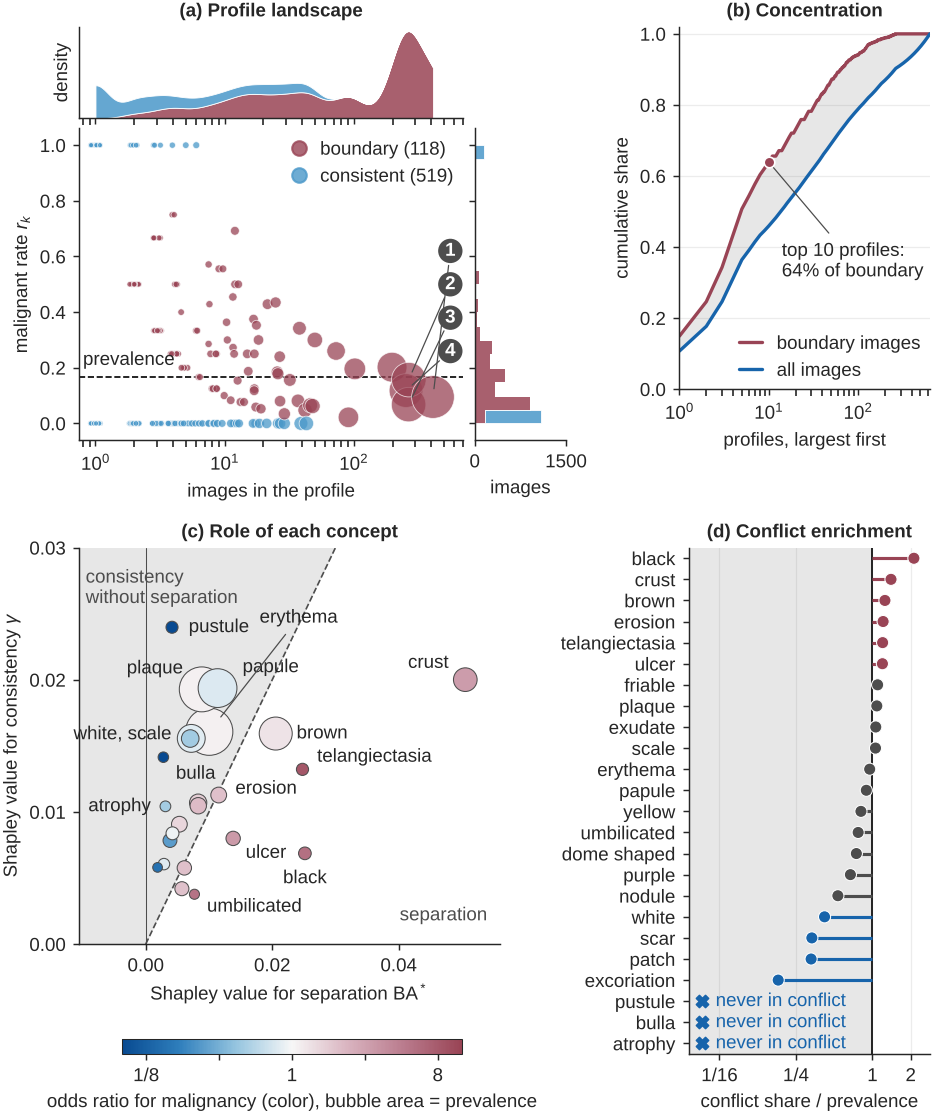

In [13]:
H = 7.55
X = images[E].values
ids, n0, n1 = profile_counts(X, y)
nk = n0 + n1
r = n1 / nk
inc = (n0 > 0) & (n1 > 0)
prof = pd.DataFrame({"n": nk, "r": r, "status": np.where(inc, "boundary", "consistent")})
rng = np.random.default_rng(4)
prof["nj"] = prof.n * np.exp(rng.uniform(-0.09, 0.09, len(prof)) * (prof.n < 30))
img = pd.DataFrame({"n": nk[ids], "r": r[ids], "status": np.where(inc[ids], "boundary", "consistent")})
PAL = {"boundary": CON, "consistent": B5}
fig = plt.figure(figsize=(W, H))

gA = fig.add_gridspec(2, 2, left=0.085, right=0.6, top=0.965, bottom=0.6, width_ratios=[4.2, 1], height_ratios=[1, 3.4],
                      hspace=0.05, wspace=0.05)
ax = fig.add_subplot(gA[1, 0])
axt = fig.add_subplot(gA[0, 0], sharex=ax)
axr = fig.add_subplot(gA[1, 1], sharey=ax)
ax.axhline(y.mean(), color=BLK, lw=0.8, ls="--", zorder=1)
sns.scatterplot(data=prof.sort_values("n"), x="nj", y="r", hue="status", palette=PAL, size="n", sizes=(6, 420), size_norm=(1, 411),
                alpha=0.75, edgecolor="white", linewidth=0.4, ax=ax, legend=False, zorder=3)
ax.set_xscale("log"); ax.set_xlim(0.75, 700); ax.set_ylim(-0.06, 1.06)
ax.set_xlabel("images in the profile"); ax.set_ylabel("malignant rate $r_k$")
ax.text(0.8, y.mean() + 0.03, "prevalence", va="bottom")
spots = [(560, 0.62), (560, 0.5), (560, 0.38), (560, 0.26)]
for i, k in enumerate(np.argsort(-nk)[:4]):
    ax.annotate("", (nk[k], r[k]), xytext=spots[i], arrowprops=dict(arrowstyle="-", color=DG, lw=0.6, shrinkB=4, shrinkA=7))
    badge(ax, *spots[i], str(i + 1), fc=DG)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=CON, alpha=0.8, ms=7, label=f"boundary ({inc.sum()})"),
                   Line2D([], [], marker="o", ls="", color=B5, alpha=0.8, ms=7, label=f"consistent ({(~inc).sum()})")],
          loc="upper right", bbox_to_anchor=(1.0, 0.99), handletextpad=0.1, borderaxespad=0.1)
sns.kdeplot(data=img, x="n", hue="status", palette=PAL, multiple="stack", log_scale=True, bw_adjust=0.8, fill=True, alpha=0.85,
            linewidth=0.4, ax=axt, legend=False, common_norm=True, cut=0)
axt.set_ylabel("density"); axt.set_xlabel(""); plt.setp(axt.get_xticklabels(), visible=False); axt.set_yticks([])
sns.histplot(data=img, y="r", hue="status", palette=PAL, multiple="stack", bins=np.linspace(0, 1, 21), element="step", alpha=0.85,
             linewidth=0.4, ax=axr, legend=False)
axr.set_xlabel("images"); axr.set_ylabel(""); plt.setp(axr.get_yticklabels(), visible=False); axr.set_xticks([0, 1500])
axt.set_title("(a) Profile landscape")

ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.72, right=0.985, top=0.965, bottom=0.645)[0])
order = np.argsort(-nk)
xs = np.arange(1, len(order) + 1)
bshare = np.cumsum((nk * inc)[order]) / (nk * inc).sum()
ishare = np.cumsum(nk[order]) / nk.sum()
cb = pd.DataFrame({"k": np.r_[xs, xs], "share": np.r_[bshare, ishare], "curve": ["boundary images"] * len(xs) + ["all images"] * len(xs)})
ax.fill_between(xs, bshare, ishare, **SHADE)
sns.lineplot(data=cb, x="k", y="share", hue="curve", palette={"boundary images": CON, "all images": B7}, lw=1.6, ax=ax, legend=False)
ax.scatter([10], [bshare[9]], s=26, color=CON, zorder=5, edgecolor="white")
ax.annotate(f"top 10 profiles:\n{100 * bshare[9]:.0f}% of boundary", (10, bshare[9]), xytext=(14, 0.36), ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=DG, lw=0.6, shrinkB=3))
ax.legend(handles=[Line2D([], [], color=CON, lw=1.6, label="boundary images"), Line2D([], [], color=B7, lw=1.6, label="all images")],
          loc="lower right", handlelength=1.2, borderaxespad=0.1)
ax.set_xscale("log"); ax.set_xlim(1, 637); ax.set_ylim(0, 1.02)
ax.set_xlabel("profiles, largest first"); ax.set_ylabel("cumulative share")
ax.grid(axis="y"); ax.set_title("(b) Concentration")

participation = read(ANALYSIS / "conflict_participation.csv").set_index("concept")
odds = read(ANALYSIS / "concepts.csv").set_index("concept").odds_ratio
d = pd.DataFrame({"ba": shapley.ba, "gamma": shapley.gamma, "prev": participation.prevalence.reindex(shapley.index)})
d["lor"] = np.log2(odds.reindex(shapley.index)).clip(-4, 4)
ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.085, right=0.53, top=0.505, bottom=0.155)[0])
lim, x0 = 0.056, -0.0105
ax.fill_between([x0, lim], [x0, lim], [lim, lim], **SHADE)
ax.plot([0, lim], [0, lim], color=DG, lw=0.8, ls="--"); ax.axvline(0, color=DG, lw=0.5)
sns.scatterplot(data=d, x="ba", y="gamma", hue="lor", palette=CMAP, hue_norm=Normalize(-3.5, 3.5), size="prev", sizes=(20, 520),
                size_norm=(0.01, 0.62), edgecolor=DG, linewidth=0.5, ax=ax, legend=False, zorder=3)
offsets = {"crust": (-8, 8, "right"), "black": (0, -12, "center"), "telangiectasia": (7, 6, "left"),
           "brown_hyperpigmentation": (10, 0, "left"), "pustule": (8, 0, "left"), "papule": (12, 10, "left"),
           "plaque": (-9, 10, "right"), "white_hypopigmentation": (-9, 2, "right"), "bulla": (6, -8, "left"),
           "ulcer": (6, -7, "left"), "erosion": (8, 3, "left"), "atrophy": (-7, 0, "right"), "umbilicated": (6, -6, "left")}
for c, (dx, dy, ha) in offsets.items():
    ax.annotate("white, scale" if c == "white_hypopigmentation" else nice(c), (d.ba[c], d.gamma[c]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center", zorder=6)
ax.annotate("erythema", (d.ba["erythema"], d.gamma["erythema"]), xytext=(0.018, 0.0247), textcoords="data", ha="left", va="center",
            arrowprops=dict(arrowstyle="-", color=DG, lw=0.6, shrinkB=9), zorder=6)
ax.set_xlim(x0, lim); ax.set_ylim(0, 0.03); ax.set_xticks([0, 0.02, 0.04]); ax.set_yticks([0, 0.01, 0.02, 0.03])
ax.set_xlabel(r"Shapley value for separation $\mathrm{BA}^*$"); ax.set_ylabel(r"Shapley value for consistency $\gamma$")
ax.text(-0.0095, 0.0285, "consistency\nwithout separation", va="top", color=DG)
ax.text(0.054, 0.0018, "separation", ha="right", color=DG)
ax.set_title("(c) Role of each concept")
cax = fig.add_axes([0.13, 0.058, 0.36, 0.013])
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=Normalize(-3.5, 3.5)), cax=cax, orientation="horizontal")
cbar.set_ticks([-3, -1.5, 0, 1.5, 3]); cbar.set_ticklabels(["1/8", "", "1", "", "8"]); cbar.outline.set_linewidth(0.5)
cbar.set_label("odds ratio for malignancy (color), bubble area = prevalence")

ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.73, right=0.985, top=0.505, bottom=0.058)[0])
e = participation.reindex(shapley.index).copy()
e["ratio"] = e.conflict_share / e.prevalence
e = e.sort_values("ratio", ascending=False)
e["yy"] = np.arange(len(e))
e["never"] = e.conflict_share == 0
e["x"] = np.log2(e.ratio.clip(lower=2 ** -4.6))
e["kind"] = np.where(e.x > 0.2, "over", np.where(e.x < -1, "under", "prop"))
kind_color = {"over": CON, "under": B7, "prop": DG}
ax.axvspan(-5, 0, **SHADE); ax.axvline(0, color=BLK, lw=0.8)
ax.hlines(e.yy[~e.never], 0, e.x[~e.never], colors=[kind_color[k] for k in e.kind[~e.never]], lw=1.5)
sns.scatterplot(data=e[~e.never], x="x", y="yy", hue="kind", palette=kind_color, s=34, edgecolor="white", linewidth=0.5, ax=ax,
                legend=False, zorder=3)
ax.scatter(np.full(e.never.sum(), -4.45), e.yy[e.never], marker="X", s=34, color=B7, zorder=3)
for yv in e.yy[e.never]:
    ax.text(-4.1, yv, "never in conflict", va="center", color=B7)
ax.set_xlim(-4.8, 1.5); ax.set_xticks([-4, -2, 0, 1]); ax.set_xticklabels(["1/16", "1/4", "1", "2"])
ax.set_yticks(e.yy); ax.set_yticklabels([nice(c) for c in e.index]); ax.set_ylim(len(e) - 0.5, -0.5); ax.set_ylabel("")
ax.set_xlabel("conflict share / prevalence"); ax.grid(axis="x"); ax.set_title("(d) Conflict enrichment")
save(fig, "fig1_structure")

Figure 2, detectability of each malignant group.

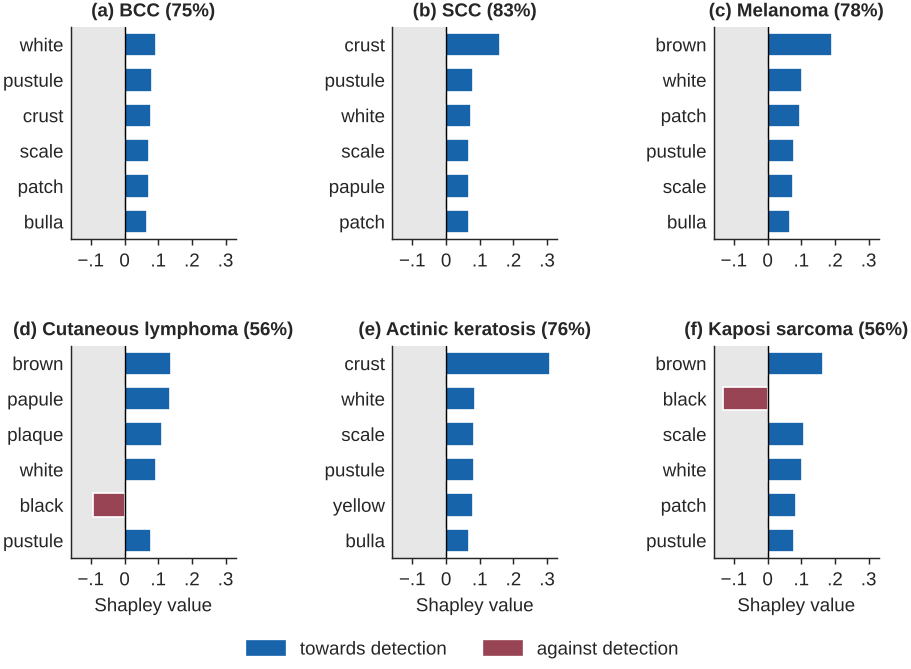

In [14]:
fig, axs = plt.subplots(2, 3, figsize=(W, 4.6))
fig.subplots_adjust(left=0.135, right=0.99, top=0.94, bottom=0.17, wspace=0.95, hspace=0.5)
for i, (ax, g) in enumerate(zip(axs.ravel(), GROUPS)):
    s = shapley[f"det|{g}"]
    top = s.reindex(s.abs().sort_values(ascending=False).index[:6])
    d = pd.DataFrame({"c": [nice(c) for c in top.index], "v": top.values, "sign": np.where(top.values > 0, "towards", "against")})
    ax.axvspan(-0.18, 0, **SHADE)
    sns.barplot(data=d, y="c", x="v", hue="sign", palette={"towards": B7, "against": CON}, width=0.66, ax=ax, legend=False,
                saturation=1, orient="h")
    ax.axvline(0, color=BLK, lw=0.7)
    ax.set_xlim(-0.16, 0.33); ax.set_xticks([-0.1, 0, 0.1, 0.2, 0.3]); ax.set_xticklabels(["$-$.1", "0", ".1", ".2", ".3"])
    ax.set_ylabel(""); ax.set_xlabel("Shapley value" if i >= 3 else ""); ax.tick_params(axis="y", length=0)
    ax.set_title(f"({LETTERS[i]}) {g} ({100 * s.sum():.0f}%)")
fig.legend(handles=[Patch(color=B7, label="towards detection"), Patch(color=CON, label="against detection")], loc="lower center",
           ncol=2, bbox_to_anchor=(0.55, 0.0))
save(fig, "fig2_detectability")

Figure 3, profiles that hold most forced misses.

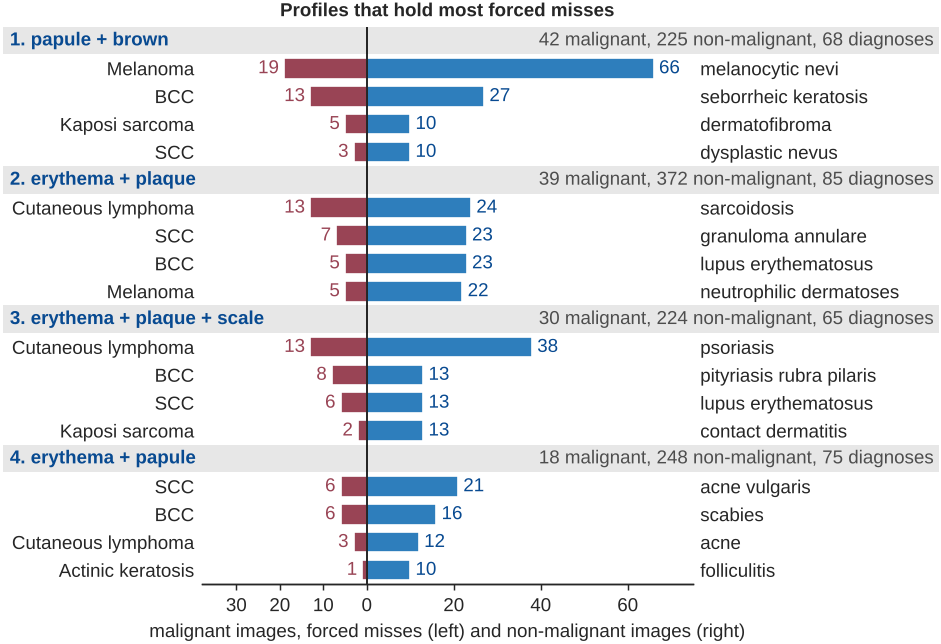

In [15]:
P_, N_ = y.sum(), len(y) - y.sum()
forced = (y == 1) & ~(n1 / P_ > n0 / N_)[ids]
top = pd.Series(ids[forced]).value_counts().index[:4]
short = {"seborrheic keratosis": "seborrheic keratosis", "erythema annulare centrifigum": "erythema annulare",
         "pityriasis rubra pilaris": "pityriasis rubra pilaris", "allergic contact dermatitis": "contact dermatitis",
         "neutrophilic dermatoses": "neutrophilic dermatoses"}
rows, heads, ypos = [], [], 0
for i, k in enumerate(top):
    m = ids == k
    mal = images.malignant_group[m & (y == 1)].value_counts().head(4)
    non = images.dx[m & (y == 0)].value_counts().head(4)
    profile = " + ".join(nice(c) for c, v in zip(E, X[m][0]) if v)
    heads.append((ypos, f"{i + 1}. {profile}", f"{int(n1[k])} malignant, {int(n0[k])} non-malignant, {images.dx[m].nunique()} diagnoses"))
    ypos += 1
    for j in range(4):
        rows.append({"yy": ypos, "mal": -mal.values[j] if j < len(mal) else 0, "non": non.values[j],
                     "ml": mal.index[j] if j < len(mal) else "", "nl": short.get(non.index[j], non.index[j])})
        ypos += 1
bars = pd.DataFrame(rows)
fig = plt.figure(figsize=(W, 4.45))
ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.215, right=0.735, top=0.945, bottom=0.11)[0])
bt = blended_transform_factory(ax.transAxes, ax.transData)
for y0, t1, t2 in heads:
    ax.add_patch(Rectangle((-0.404, y0 - 0.5), 1.904, 1.0, transform=bt, clip_on=False, facecolor=DG, alpha=0.13, lw=0))
    ax.text(-0.39, y0, t1, transform=bt, ha="left", va="center", fontweight="bold", color=B9)
    ax.text(1.49, y0, t2, transform=bt, ha="right", va="center", color=DG)
sns.barplot(data=bars, y="yy", x="mal", orient="h", color=CON, width=0.74, ax=ax, saturation=1, native_scale=True)
sns.barplot(data=bars, y="yy", x="non", orient="h", color=B6, width=0.74, ax=ax, saturation=1, native_scale=True)
for _, q in bars.iterrows():
    if q.mal:
        ax.text(q.mal - 1.2, q.yy, f"{-int(q.mal)}", ha="right", va="center", color=CON)
    ax.text(q.non + 1.2, q.yy, f"{int(q.non)}", ha="left", va="center", color=B9)
ax.axvline(0, color=BLK, lw=0.8); ax.set_xlim(-38, 75); ax.set_ylim(ypos - 0.5, -0.5)
ax.set_xticks([-30, -20, -10, 0, 20, 40, 60]); ax.set_xticklabels(["30", "20", "10", "0", "20", "40", "60"])
ax.set_yticks(bars.yy); ax.set_yticklabels(bars.ml); ax.set_ylabel("")
ax.set_xlabel("malignant images, forced misses (left) and non-malignant images (right)")
axr = ax.twinx(); axr.set_ylim(ax.get_ylim()); axr.set_yticks(bars.yy); axr.set_yticklabels(bars.nl)
for a in (ax, axr):
    a.tick_params(axis="y", length=0)
sns.despine(ax=ax, left=True); sns.despine(ax=axr, left=True, right=True)
ax.set_title("Profiles that hold most forced misses")
save(fig, "fig3_collisions")

Figure 4, decision maps of the concept space after each filter.

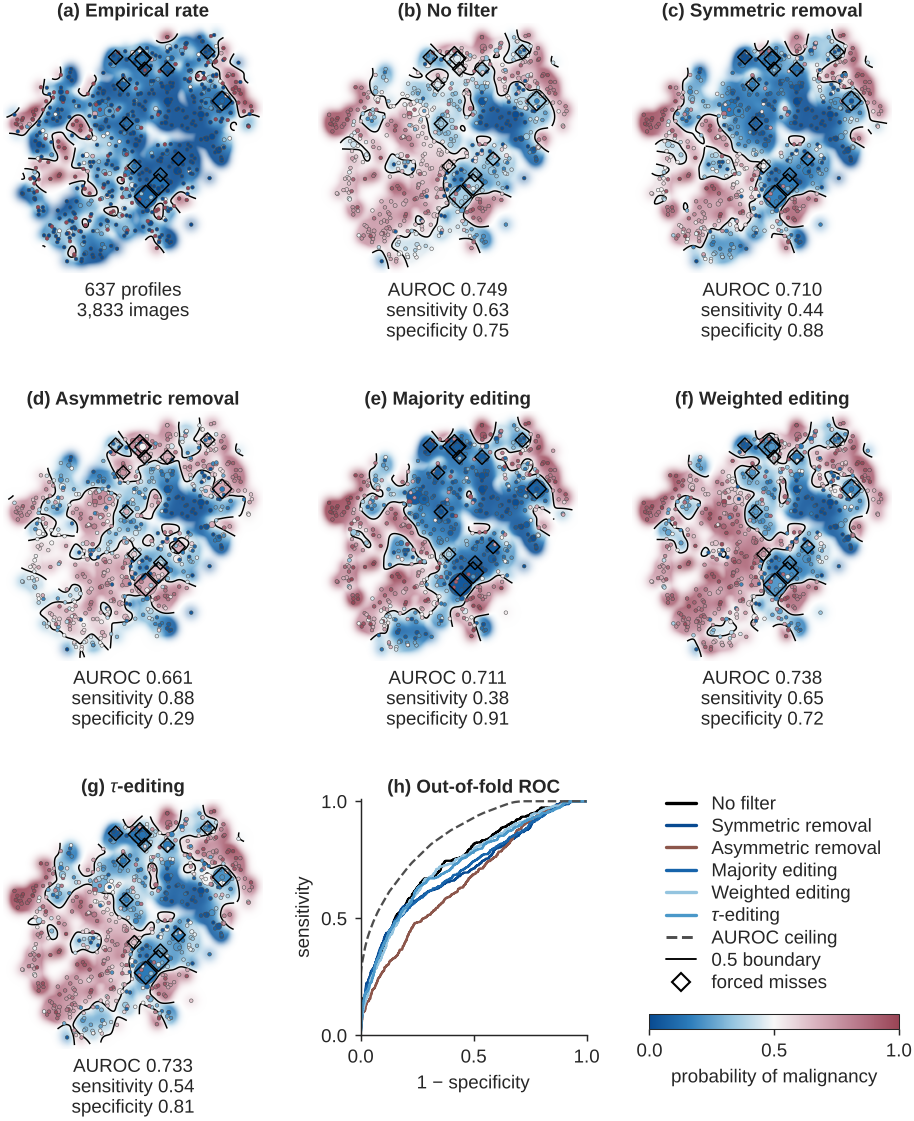

In [16]:
Zp = maps[["tsne_x", "tsne_y"]].values
forced_in_profile = np.array([images.forced_miss.values[profile_u == k].sum() for k in range(len(images_u))])
lo = np.percentile(Zp, 0.5, axis=0) - 0.25
hi = np.percentile(Zp, 99.5, axis=0) + 0.25
gx, gy = np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300)
GX, GY = np.meshgrid(gx, gy)
G = np.c_[GX.ravel(), GY.ravel()]
K = np.exp(-((G[:, None, :] - Zp[None, :, :]) ** 2).sum(-1) / (2 * 0.09 ** 2)) * np.sqrt(images_u)[None, :]
density = K.sum(1)
alpha = np.clip(density / np.quantile(density, 0.55), 0, 1).reshape(GX.shape)
field = lambda v: ((K * v[None, :]).sum(1) / np.maximum(density, 1e-12)).reshape(GX.shape)
fig = plt.figure(figsize=(W, 7.75))
gs = fig.add_gridspec(3, 3, wspace=0.06, hspace=0.55, left=0.01, right=0.99, top=0.968, bottom=0.085)
for idx, (key, title) in enumerate([("rate", "Empirical rate")] + [(h, FILTER_LABEL[h]) for h in FILTERS]):
    ax = fig.add_subplot(gs[idx // 3, idx % 3])
    v = rate_u if key == "rate" else maps[f"map_{key}"].values
    F_ = field(v)
    rgba = CMAP(np.clip(F_, 0, 1))
    rgba[..., 3] = alpha * 0.9
    ax.imshow(rgba, extent=[gx[0], gx[-1], gy[0], gy[-1]], origin="lower", interpolation="bilinear")
    ax.contour(GX, GY, np.where(alpha > 0.2, F_, np.nan), levels=[0.5], colors=BLK, linewidths=0.7)
    pts = pd.DataFrame({"x": Zp[:, 0], "y": Zp[:, 1], "v": v, "n": images_u})
    sns.scatterplot(data=pts, x="x", y="y", hue="v", palette=CMAP, hue_norm=(0, 1), size="n", sizes=(3, 120), size_norm=(1, 411),
                    edgecolor=DG, linewidth=0.25, ax=ax, legend=False, zorder=3)
    mm = forced_in_profile >= 2
    ax.scatter(Zp[mm, 0], Zp[mm, 1], s=10 + np.sqrt(forced_in_profile[mm]) * 8, facecolor="none", edgecolor=BLK, linewidths=0.7,
               marker="D", zorder=4)
    ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gy[0], gy[-1]); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    sns.despine(ax=ax, left=True, bottom=True)
    ax.set_title(f"({LETTERS[idx]}) {title}", pad=3)
    text = (f"{len(images_u)} profiles\n{thousands(n_img)} images" if key == "rate" else
            f"AUROC {oof.loc[key].auroc:.3f}\nsensitivity {oof.loc[key].sensitivity:.2f}\nspecificity {oof.loc[key].specificity:.2f}")
    ax.text(0.5, -0.03, text, transform=ax.transAxes, va="top", ha="center")
ax = fig.add_subplot(gs[2, 1])
p_ = ax.get_position()
ax.set_position([p_.x0 + 0.065, p_.y0 + 0.012, p_.width - 0.075, p_.height - 0.012])
curves = []
for h in FILTERS:
    f, t, _ = roc_curve(scores.y, scores[f"oof_{h}"])
    curves.append(pd.DataFrame({"f": f, "t": t, "h": h}))
sns.lineplot(data=pd.concat(curves), x="f", y="t", hue="h", palette=FILTER_COLOR, lw=1.1, ax=ax, legend=False, estimator=None, sort=False)
f, t, _ = roc_curve(scores.y, rate_u[profile_u])
ax.plot(f, t, color=DG, lw=1.1, ls="--")
ax.set_xlabel("1 $-$ specificity"); ax.set_ylabel("sensitivity"); ax.set_title("(h) Out-of-fold ROC", pad=3)
ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax = fig.add_subplot(gs[2, 2])
ax.axis("off")
handles = [Line2D([], [], color=FILTER_COLOR[h], lw=1.6, label=FILTER_LABEL[h]) for h in FILTERS] + [
    Line2D([], [], color=DG, ls="--", lw=1.4, label="AUROC ceiling"), Line2D([], [], color=BLK, lw=0.9, label="0.5 boundary"),
    Line2D([], [], marker="D", ls="", mfc="none", mec=BLK, ms=6, label="forced misses")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.12, 1.08), ncol=1, labelspacing=0.25, handlelength=1.6)
cax = ax.inset_axes([0.12, 0.08, 0.84, 0.06])
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP, norm=Normalize(0, 1)), cax=cax, orientation="horizontal")
cbar.set_ticks([0, 0.5, 1]); cbar.outline.set_linewidth(0.5); cbar.set_label("probability of malignancy")
save(fig, "fig4_decision_maps")

Figure 5, predicted probability of each profile against its malignant rate.

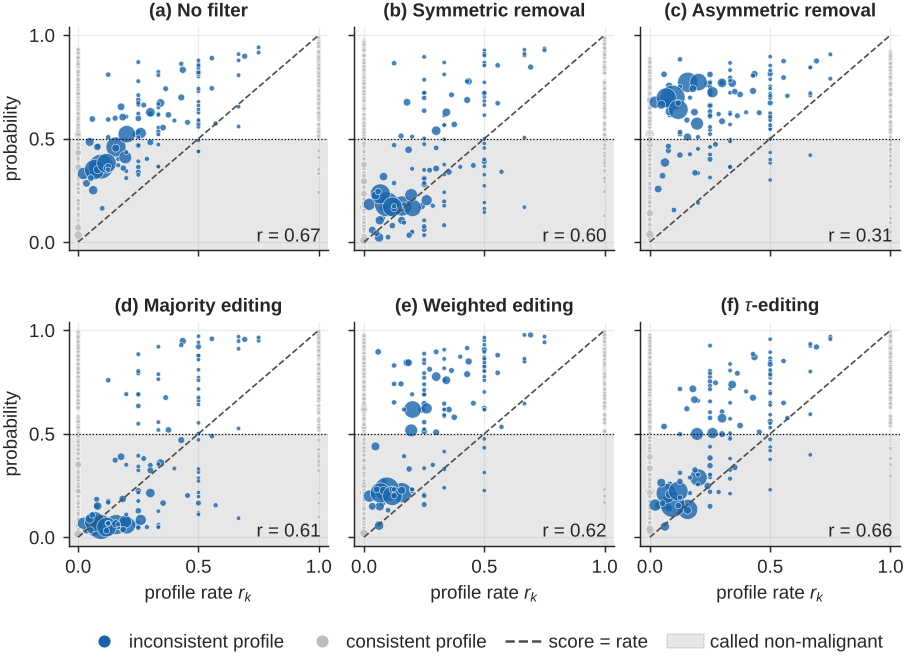

In [17]:
mixed_u = (malignant_u > 0) & (malignant_u < images_u)
fig, axs = plt.subplots(2, 3, figsize=(W, 4.55), sharex=True, sharey=True)
fig.subplots_adjust(left=0.11, right=0.99, top=0.94, bottom=0.18, wspace=0.1, hspace=0.32)
for i, (ax, h) in enumerate(zip(axs.ravel(), FILTERS)):
    v = maps[f"map_{h}"].values
    d = pd.DataFrame({"r": rate_u, "v": v, "n": images_u, "kind": np.where(mixed_u, "inconsistent", "consistent")})
    ax.axhspan(-0.04, 0.5, **SHADE)
    ax.plot([0, 1], [0, 1], color=DG, lw=0.8, ls="--"); ax.axhline(0.5, color=BLK, lw=0.6, ls=":")
    sns.scatterplot(data=d.sort_values("kind"), x="r", y="v", hue="kind", palette={"inconsistent": B7, "consistent": "#bdbdbd"},
                    size="n", sizes=(4, 140), size_norm=(1, 411), alpha=0.8, edgecolor="white", linewidth=0.3, ax=ax, legend=False)
    rho = np.corrcoef(rate_u[mixed_u], v[mixed_u])[0, 1]
    ax.set_title(f"({LETTERS[i]}) {FILTER_LABEL[h]}"); ax.text(0.97, 0.04, f"r = {rho:.2f}", transform=ax.transAxes, ha="right")
    ax.set_xlim(-0.04, 1.04); ax.set_ylim(-0.04, 1.04); ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1])
    ax.set_xlabel("profile rate $r_k$" if i >= 3 else ""); ax.set_ylabel("probability" if i % 3 == 0 else ""); ax.grid(True)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=B7, label="inconsistent profile"),
                    Line2D([], [], marker="o", ls="", color="#bdbdbd", label="consistent profile"),
                    Line2D([], [], color=DG, ls="--", label="score = rate"), Patch(color=DG, alpha=0.13, label="called non-malignant")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.55, 0.0), columnspacing=1.0, handletextpad=0.3)
save(fig, "fig5_score_collapse")

Figure 6, clinical cost of filtering.

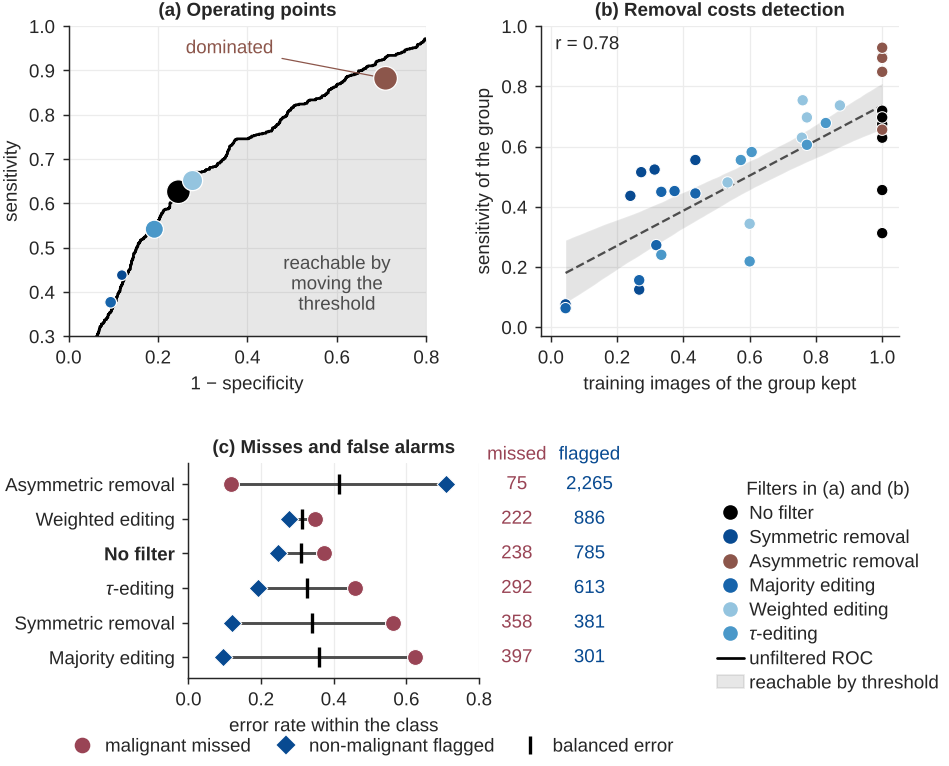

In [18]:
retained = read(ANALYSIS / "filter_retention.csv").pivot(index="group", columns="filter", values="retained")
fig = plt.figure(figsize=(6.15, 5.3))
gs = fig.add_gridspec(1, 2, left=0.085, right=0.985, top=0.955, bottom=0.565, wspace=0.32)
ax = fig.add_subplot(gs[0])
f, t, _ = roc_curve(scores.y, scores.oof_none)
ax.fill_between(f, 0, t, **SHADE)
sns.lineplot(x=f, y=t, color=BLK, lw=1.3, ax=ax, estimator=None)
pts = pd.DataFrame({"h": FILTERS, "fpr": [1 - oof.loc[h, "specificity"] for h in FILTERS], "tpr": [oof.loc[h, "sensitivity"] for h in FILTERS],
                    "kept": [training.loc[h, "train_malignant_kept"] for h in FILTERS]})
sns.scatterplot(data=pts, x="fpr", y="tpr", hue="h", palette=FILTER_COLOR, size="kept", sizes=(25, 130), size_norm=(100, 354),
                edgecolor="white", linewidth=0.6, ax=ax, legend=False, zorder=5)
ax.text(0.6, 0.36, "reachable by\nmoving the\nthreshold", ha="center", color=DG)
ax.annotate("dominated", (pts.fpr[2], pts.tpr[2]), xytext=(0.36, 0.95), ha="center", va="center", color=BRN,
            arrowprops=dict(arrowstyle="-", color=BRN, lw=0.6, shrinkB=6))
ax.set_xlim(0, 0.8); ax.set_ylim(0.3, 1.0); ax.set_xlabel("1 $-$ specificity"); ax.set_ylabel("sensitivity"); ax.grid(True)
ax.set_title("(a) Operating points")

ax = fig.add_subplot(gs[1])
pairs = pd.DataFrame([{"h": h, "g": g, "kept": retained.loc[g, h], "sens": oof.loc[h, g]} for h in FILTERS for g in GROUPS])
sns.regplot(data=pairs, x="kept", y="sens", scatter=False, color=DG, line_kws=dict(lw=1.1, ls="--"), ci=95, n_boot=1000, seed=0, ax=ax)
sns.scatterplot(data=pairs, x="kept", y="sens", hue="h", palette=FILTER_COLOR, s=30, edgecolor="white", linewidth=0.5, ax=ax,
                legend=False, zorder=4)
rho = np.corrcoef(pairs.kept, pairs.sens)[0, 1]
ax.text(0.04, 0.97, f"r = {rho:.2f}", transform=ax.transAxes, va="top")
ax.set_xlim(-0.03, 1.05); ax.set_ylim(-0.03, 1.0); ax.set_xlabel("training images of the group kept"); ax.set_ylabel("sensitivity of the group")
ax.grid(True); ax.set_title("(b) Removal costs detection")

ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.215, right=0.53, top=0.405, bottom=0.135)[0])
dd = pd.DataFrame({"h": FILTERS, "miss": [1 - oof.loc[h, "sensitivity"] for h in FILTERS], "fa": [1 - oof.loc[h, "specificity"] for h in FILTERS]})
dd = dd.sort_values("miss").reset_index(drop=True)
dd["yy"] = np.arange(len(dd))[::-1]
dd["mid"] = (dd.miss + dd.fa) / 2
for _, r_ in dd.iterrows():
    ax.plot([r_.miss, r_.fa], [r_.yy, r_.yy], color=DG, lw=1.4, solid_capstyle="round", zorder=2)
sns.scatterplot(data=dd, x="fa", y="yy", color=B9, marker="D", s=40, edgecolor="white", linewidth=0.5, ax=ax, zorder=4)
sns.scatterplot(data=dd, x="miss", y="yy", color=CON, marker="o", s=58, edgecolor="white", linewidth=0.5, ax=ax, zorder=5)
sns.scatterplot(data=dd, x="mid", y="yy", color=BLK, marker="|", s=90, linewidth=1.6, ax=ax, zorder=6)
ax.set_yticks(dd.yy); ax.set_yticklabels([FILTER_LABEL[h] for h in dd.h])
for tick in ax.get_yticklabels():
    if tick.get_text() == "No filter":
        tick.set_fontweight("bold")
ax.set_ylim(-0.6, len(dd) - 0.4); ax.set_xlim(0, 0.8); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8])
ax.set_xlabel("error rate within the class"); ax.set_ylabel(""); ax.grid(axis="x"); ax.set_title("(c) Misses and false alarms")
tr = ax.get_yaxis_transform()
ax.text(1.13, len(dd) - 0.4, "missed", transform=tr, ha="center", va="bottom", color=CON)
ax.text(1.38, len(dd) - 0.4, "flagged", transform=tr, ha="center", va="bottom", color=B9)
for _, r_ in dd.iterrows():
    ax.text(1.13, r_.yy, f"{r_.miss * n_mal:.0f}", transform=tr, ha="center", va="center", color=CON)
    ax.text(1.38, r_.yy, f"{r_.fa * (n_img - n_mal):,.0f}", transform=tr, ha="center", va="center", color=B9)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=CON, ms=6.5, label="malignant missed"),
                   Line2D([], [], marker="D", ls="", color=B9, ms=5.5, label="non-malignant flagged"),
                   Line2D([], [], marker="|", ls="", color=BLK, ms=9, mew=1.6, label="balanced error")],
          loc="upper center", bbox_to_anchor=(0.62, -0.2), ncol=3, columnspacing=0.9, handletextpad=0.2, frameon=False)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=FILTER_COLOR[h], ms=6, label=FILTER_LABEL[h]) for h in FILTERS]
           + [Line2D([], [], color=BLK, lw=1.3, label="unfiltered ROC"), Patch(color=DG, alpha=0.13, label="reachable by threshold")],
           loc="center left", ncol=1, bbox_to_anchor=(0.77, 0.25), handletextpad=0.3, handlelength=1.4, labelspacing=0.35,
           title="Filters in (a) and (b)")
save(fig, "fig6_filter_cost")

Figure 7, concept bottleneck models on the test images.

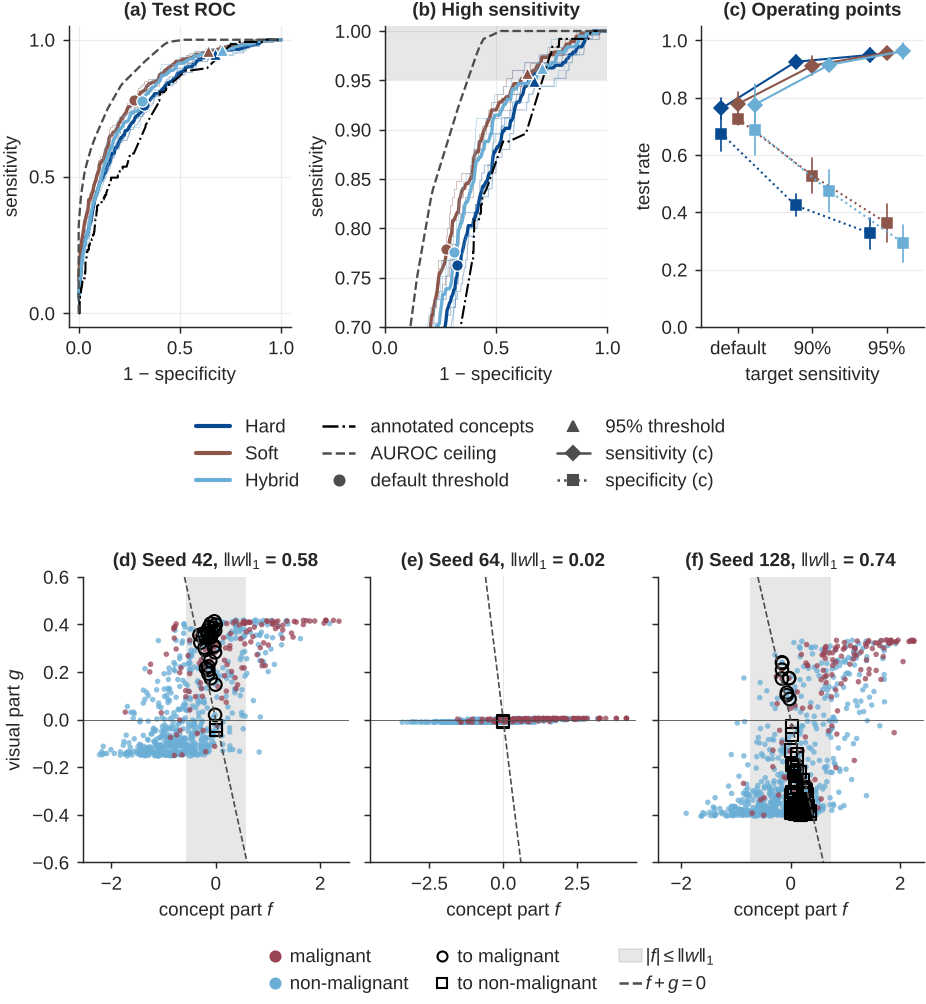

In [19]:
roc = read(ANALYSIS / "roc_curves.csv")
curve = lambda name: (roc[roc.curve == name].fpr.values, roc[roc.curve == name].tpr.values)
points = read(ANALYSIS / "operating_points.csv")
hybrid = read(ANALYSIS / "hybrid_parts.csv")
w_l1 = read(ANALYSIS / "hybrid_weights.csv").set_index("seed").w_l1
grid = np.linspace(0, 1, 201)
fig = plt.figure(figsize=(W, 6.8))
g1 = fig.add_gridspec(1, 3, left=0.085, right=0.99, top=0.955, bottom=0.66, wspace=0.42)
axs = [fig.add_subplot(g1[i]) for i in range(3)]
for zoom, ax in zip([False, True], axs[:2]):
    if zoom:
        ax.axhspan(0.95, 1.01, **SHADE)
    for m in MODELS:
        seeds = []
        for s in (42, 64, 128):
            f, t = curve(f"{m}_{s}")
            seeds.append(pd.DataFrame({"f": grid, "t": np.interp(grid, f, t), "s": s}))
            ax.plot(f, t, color=MODEL_COLOR[m], lw=0.5, alpha=0.35)
        sns.lineplot(data=pd.concat(seeds), x="f", y="t", color=MODEL_COLOR[m], lw=1.6, errorbar=None, ax=ax)
        for target, marker in [(0.0, "o"), (0.95, "^")]:
            q = points[(points.model == m) & (points.target == target)]
            ax.plot(1 - q.specificity.mean(), q.sensitivity.mean(), marker, color=MODEL_COLOR[m], ms=5.5, mec="white", mew=0.6, zorder=5)
    f, t = curve("annotated")
    ax.plot(f, t, color=BLK, lw=1.0, ls="-.")
    f, t = curve("ceiling")
    ax.plot(f, t, color=DG, lw=1.1, ls="--")
    ax.set_xlabel("1 $-$ specificity"); ax.set_ylabel("sensitivity"); ax.set_xticks([0, .5, 1]); ax.grid(True)
    if zoom:
        ax.set_xlim(0, 1); ax.set_ylim(0.7, 1.005); ax.set_title("(b) High sensitivity")
    else:
        ax.set_yticks([0, .5, 1]); ax.set_title("(a) Test ROC")
ax = axs[2]
rows = []
for m in MODELS:
    for target, tl in [(0.0, "default"), (0.90, "90%"), (0.95, "95%")]:
        for _, r_ in points[(points.model == m) & (points.target == target)].iterrows():
            rows += [{"m": m, "t": tl, "metric": "sensitivity", "v": r_.sensitivity}, {"m": m, "t": tl, "metric": "specificity", "v": r_.specificity}]
d = pd.DataFrame(rows)
for metric, marker, ls in [("sensitivity", "D", "-"), ("specificity", "s", ":")]:
    sns.pointplot(data=d[d.metric == metric], x="t", y="v", hue="m", palette=MODEL_COLOR, dodge=0.45, markers=marker, linestyles=ls,
                  errorbar="sd", err_kws=dict(lw=0.8), markersize=4.5, linewidth=1.0, ax=ax, legend=False)
ax.set_ylim(0, 1.05); ax.set_xlabel("target sensitivity"); ax.set_ylabel("test rate"); ax.grid(axis="y"); ax.set_title("(c) Operating points")
fig.legend(handles=[Line2D([], [], color=MODEL_COLOR["hard"], lw=2, label="Hard"), Line2D([], [], color=MODEL_COLOR["soft"], lw=2, label="Soft"),
                    Line2D([], [], color=MODEL_COLOR["hybrid"], lw=2, label="Hybrid"), Line2D([], [], color=BLK, ls="-.", label="annotated concepts"),
                    Line2D([], [], color=DG, ls="--", label="AUROC ceiling"), Line2D([], [], marker="o", ls="", color=DG, label="default threshold"),
                    Line2D([], [], marker="^", ls="", color=DG, label="95% threshold"), Line2D([], [], marker="D", ls="-", color=DG, label="sensitivity (c)"),
                    Line2D([], [], marker="s", ls=":", color=DG, label="specificity (c)")],
           loc="center", ncol=3, bbox_to_anchor=(0.5, 0.535), columnspacing=1.2, handlelength=1.8)
g2 = fig.add_gridspec(1, 3, left=0.1, right=0.99, top=0.415, bottom=0.135, wspace=0.08)
hx = [fig.add_subplot(g2[0])]
hx += [fig.add_subplot(g2[i], sharey=hx[0]) for i in (1, 2)]
for i, (ax, s) in enumerate(zip(hx, (42, 64, 128))):
    h = hybrid[hybrid.seed == s].copy()
    w = w_l1[s]
    lim = np.abs(h.concept_part).max() * 1.08
    gl = 0.6
    ax.axvspan(-w, w, **SHADE); ax.plot([-gl, gl], [gl, -gl], color=DG, lw=0.8, ls="--"); ax.axhline(0, color=DG, lw=0.4)
    h["cls"] = np.where(h.y_true == 1, "malignant", "non-malignant")
    sns.scatterplot(data=h.sort_values("cls", ascending=False), x="concept_part", y="visual_part", hue="cls",
                    palette={"malignant": CON, "non-malignant": B4}, s=7, edgecolor="none", alpha=0.75, ax=ax, legend=False)
    changed = h[np.sign(h.concept_part) != np.sign(h.logit)]
    up, down = changed[changed.logit > 0], changed[changed.logit <= 0]
    ax.scatter(up.concept_part, up.visual_part, s=36, facecolor="none", edgecolor=BLK, lw=1.0)
    ax.scatter(down.concept_part, down.visual_part, s=34, marker="s", facecolor="none", edgecolor=BLK, lw=1.0)
    ax.set_xlim(-lim, lim); ax.set_ylim(-gl, gl); ax.set_xlabel("concept part $f$"); ax.set_ylabel("visual part $g$" if i == 0 else "")
    if i:
        plt.setp(ax.get_yticklabels(), visible=False)
    ax.set_title(f"({LETTERS[i + 3]}) Seed {s}, $\\|w\\|_1$ = {w:.2f}")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=CON, label="malignant"), Line2D([], [], marker="o", ls="", color=B4, label="non-malignant"),
                    Line2D([], [], marker="o", ls="", mfc="none", mec=BLK, label="to malignant"),
                    Line2D([], [], marker="s", ls="", mfc="none", mec=BLK, label="to non-malignant"),
                    Patch(color=DG, alpha=0.13, label="$|f|\\leq\\|w\\|_1$"), Line2D([], [], color=DG, ls="--", label="$f+g=0$")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.53, -0.01), columnspacing=1.2, handletextpad=0.2, handlelength=1.2)
save(fig, "fig7_models")

Figure 8, missed malignancies at the default threshold.

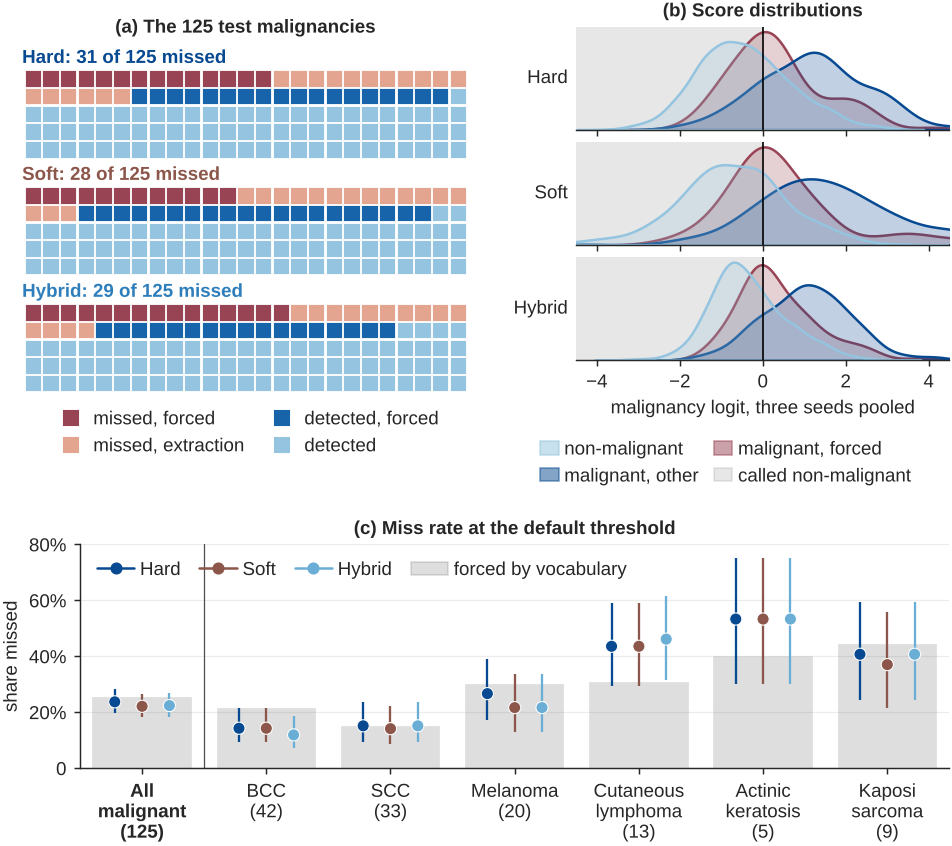

In [20]:
predictions = read(COLAB / "predictions_efficientnet_b3.csv")
test = predictions[predictions.split == "test"].copy()
test["forced"] = test.image_id.map(images.set_index("image_id").forced_miss)
miss = read(ANALYSIS / "miss_rates.csv").set_index("malignant_group")
fig = plt.figure(figsize=(W, 5.85))
ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.01, right=0.49, top=0.945, bottom=0.5)[0])
cats = ["missed, forced", "missed, extraction", "detected, forced", "detected"]
cat_color = dict(zip(cats, [CON, SALMON, B7, B3]))
rows = []
for j, m in enumerate(MODELS):
    g = test[(test.model == m) & (test.y_true == 1)].groupby("image_id").agg(miss=("y_pred", lambda v: (v == 0).sum() >= 2),
                                                                             forced=("forced", "first"))
    cat = np.where(g.miss, np.where(g.forced, cats[0], cats[1]), np.where(g.forced, cats[2], cats[3]))
    cat = sorted(cat, key=cats.index)
    y0 = -j * 6.6
    for k, c in enumerate(cat):
        rows.append({"x": k % 25, "y": y0 - k // 25, "c": c, "m": m})
    ax.text(-0.6, y0 + 1.15, f"{m.capitalize()}: {int(g.miss.sum())} of 125 missed", ha="left", va="center", fontweight="bold",
            color=MODEL_COLOR[m] if m != "hybrid" else B6)
waffle = pd.DataFrame(rows)
sns.scatterplot(data=waffle, x="x", y="y", hue="c", palette=cat_color, marker="s", s=62, edgecolor="white", linewidth=0.4, ax=ax, legend=False)
ax.set_xlim(-0.8, 24.8); ax.set_ylim(-18.2, 2.0); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("(a) The 125 test malignancies")
ax.legend(handles=[Line2D([], [], marker="s", ls="", color=cat_color[c], ms=7, label=c) for c in cats], loc="upper center",
          bbox_to_anchor=(0.5, 0.02), ncol=2, columnspacing=1.0, handletextpad=0.2)
gb = fig.add_gridspec(3, 1, left=0.6, right=0.995, top=0.945, bottom=0.565, hspace=0.12)
test["cls"] = np.where(test.y_true == 0, "non-malignant", np.where(test.forced, "malignant, forced", "malignant, other"))
pal = {"non-malignant": B3, "malignant, other": B9, "malignant, forced": CON}
for j, m in enumerate(MODELS):
    ax = fig.add_subplot(gb[j])
    d = test[test.model == m]
    ax.axvspan(-6, 0, **SHADE); ax.axvline(0, color=BLK, lw=0.8)
    sns.kdeplot(data=d, x="logit", hue="cls", palette=pal, common_norm=False, fill=True, alpha=0.25, lw=1.2, ax=ax, legend=False,
                hue_order=["non-malignant", "malignant, other", "malignant, forced"], clip=(-6, 6))
    ax.set_xlim(-4.5, 4.5); ax.set_yticks([]); ax.set_ylabel(m.capitalize(), rotation=0, ha="right", va="center")
    sns.despine(ax=ax, left=True)
    if j < 2:
        ax.set_xlabel(""); plt.setp(ax.get_xticklabels(), visible=False)
    else:
        ax.set_xlabel("malignancy logit, three seeds pooled")
    if j == 0:
        ax.set_title("(b) Score distributions")
ax.legend(handles=[Patch(facecolor=pal[k], alpha=0.5, edgecolor=pal[k], label=k) for k in pal] + [Patch(color=DG, alpha=0.13, label="called non-malignant")],
          loc="upper center", bbox_to_anchor=(0.4, -0.62), ncol=2, handlelength=1.0, handletextpad=0.3, columnspacing=0.8)
ax = fig.add_subplot(fig.add_gridspec(1, 1, left=0.075, right=0.995, top=0.355, bottom=0.1)[0])
shown = ["All malignant"] + GROUPS
miss = miss.reindex(shown)
sns.barplot(x=list(range(len(shown))), y=miss.forced.values, color=DG, alpha=0.18, width=0.8, ax=ax, saturation=1)
rows = []
for m, off in zip(MODELS, [-0.22, 0, 0.22]):
    for i, g in enumerate(shown):
        rows.append({"m": m, "x": i + off, "v": miss.loc[g, m], "lo": miss.loc[g, m + "_low"], "hi": miss.loc[g, m + "_high"]})
rows = pd.DataFrame(rows)
ax.vlines(rows.x, rows.lo, rows.hi, colors=[MODEL_COLOR[m] for m in rows.m], lw=1.1)
sns.scatterplot(data=rows, x="x", y="v", hue="m", palette=MODEL_COLOR, s=34, edgecolor="white", linewidth=0.5, ax=ax, legend=False, zorder=4)
ax.set_xticks(range(len(shown)))
breaks = {"All malignant": "All\nmalignant", "Cutaneous lymphoma": "Cutaneous\nlymphoma", "Actinic keratosis": "Actinic\nkeratosis",
          "Kaposi sarcoma": "Kaposi\nsarcoma"}
ax.set_xticklabels([f"{breaks.get(g, g)}\n({int(t)})" for g, t in zip(shown, miss.test_images)])
ax.get_xticklabels()[0].set_fontweight("bold"); ax.axvline(0.5, color=DG, lw=0.6)
ax.set_xlim(-0.5, len(shown) - 0.5); ax.set_ylim(0, 0.8); ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8]); ax.set_yticklabels(["0", "20%", "40%", "60%", "80%"])
ax.set_ylabel("share missed"); ax.set_xlabel(""); ax.grid(axis="y"); ax.set_title("(c) Miss rate at the default threshold")
ax.legend(handles=[Line2D([], [], marker="o", ls="-", color=MODEL_COLOR[m], label=m.capitalize()) for m in MODELS]
          + [Patch(color=DG, alpha=0.18, label="forced by vocabulary")], loc="upper left", ncol=4, columnspacing=1.0, handletextpad=0.3)
save(fig, "fig8_missed")